In [14]:
# Core libraries
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

# Sklearn for modeling
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import ( accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)

# NLTK for lexicon-based sentiment
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.corpus import stopwords

# Download required NLTK data
nltk.download('vader_lexicon')
nltk.download('stopwords')



[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\kingd\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kingd\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [18]:

df = pd.read_csv('Reviews.csv')
print("Raw shape:", df.shape)
display(df.head())
df.info()



Raw shape: (568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


After preprocessing: (364164, 12)


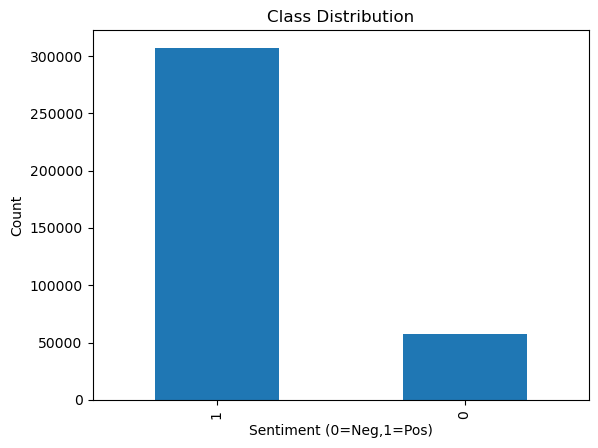

In [20]:
# 3.1 Drop duplicates & missing
df = (
    df
    .drop_duplicates(subset=['UserId','ProfileName','Time','Text'])
    .dropna(subset=['Text','Score'])
    .reset_index(drop=True)
)

# 3.2 Filter out neutral and binarize: 4–5→1 positive, 1–2→0 negative
df = df[df['Score'] != 3].copy()
df['Sentiment'] = (df['Score'] > 3).astype(int)

# 3.3 Fast text cleaning using pandas vectorized methods
stopset = set(stopwords.words('english'))
TAG_RE = r'<.*?>'
NONALPHANUM_RE = r'[^a-z0-9\s]'

def filter_stopwords(tokens):
    return ' '.join(tok for tok in tokens if tok not in stopset)

df['Cleaned'] = (
    df['Text']
    .str.lower()
    .str.replace(TAG_RE, ' ', regex=True)
    .str.replace(NONALPHANUM_RE, ' ', regex=True)
    .str.split()
    .apply(filter_stopwords)
)

print("After preprocessing:", df.shape)
df['Sentiment'].value_counts().plot.bar(title='Class Distribution')
plt.xlabel('Sentiment (0=Neg,1=Pos)')
plt.ylabel('Count')
plt.show()


In [21]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    df['Cleaned'], df['Sentiment'],
    test_size=0.20, random_state=42, stratify=df['Sentiment']
)

# Define vectorizers
count_vec = CountVectorizer(max_features=10000, ngram_range=(1,2))
tfidf_vec = TfidfVectorizer(max_features=10000, ngram_range=(1,2))


In [22]:
sia = SentimentIntensityAnalyzer()

def vader_predict(texts):
    return [1 if sia.polarity_scores(t)['compound'] >= 0 else 0 for t in texts]

v_preds = vader_predict(X_test)
print("### VADER Lexicon-Based ###")
print("Accuracy:", accuracy_score(y_test, v_preds))
print(classification_report(y_test, v_preds, digits=4))


### VADER Lexicon-Based ###
Accuracy: 0.8631526917743331
              precision    recall  f1-score   support

           0     0.6401    0.2909    0.4000     11422
           1     0.8803    0.9696    0.9228     61411

    accuracy                         0.8632     72833
   macro avg     0.7602    0.6303    0.6614     72833
weighted avg     0.8426    0.8632    0.8408     72833



In [23]:
pipelines = {
    'NB':  Pipeline([('tfidf', tfidf_vec), ('clf', MultinomialNB())]),
    'LR':  Pipeline([('tfidf', tfidf_vec), ('clf', LogisticRegression(max_iter=200))]),
    'SVM': Pipeline([('tfidf', tfidf_vec), ('clf', LinearSVC())]),
}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    print(f"=== {name} ===")
    print("Accuracy:", accuracy_score(y_test, preds))
    print(classification_report(y_test, preds, digits=4))


=== NB ===
Accuracy: 0.8957478066261173
              precision    recall  f1-score   support

           0     0.8961    0.3792    0.5329     11422
           1     0.8957    0.9918    0.9413     61411

    accuracy                         0.8957     72833
   macro avg     0.8959    0.6855    0.7371     72833
weighted avg     0.8958    0.8957    0.8773     72833

=== LR ===
Accuracy: 0.9313635302678731
              precision    recall  f1-score   support

           0     0.8537    0.6786    0.7562     11422
           1     0.9424    0.9784    0.9601     61411

    accuracy                         0.9314     72833
   macro avg     0.8981    0.8285    0.8581     72833
weighted avg     0.9285    0.9314    0.9281     72833

=== SVM ===
Accuracy: 0.9323246330646823
              precision    recall  f1-score   support

           0     0.8292    0.7160    0.7684     11422
           1     0.9485    0.9726    0.9604     61411

    accuracy                         0.9323     72833
   macr

In [28]:
results = []
# VADER
results.append({
    'Model': 'VADER',
    'Accuracy': accuracy_score(y_test, v_preds),
    'F1': f1_score(y_test, v_preds)
})
# ML models
for name, pipe in pipelines.items():
    p = pipe.predict(X_test)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, p),
        'F1': f1_score(y_test, p)
    })

res_df = pd.DataFrame(results).set_index('Model')
display(res_df)


,Accuracy,F1
Model,,
VADER,0.863153,0.922768
NB,0.895748,0.941326
LR,0.931364,0.960061
SVM,0.932325,0.960372


In [30]:
# Save cleaned data for submission
df[['Id','ProductId','Sentiment','Cleaned']].to_csv(
    'cleaned_amazon_reviews.csv', index=False
)
